In [1]:
import numpy as np

A = np.array([[3, 1],
              [0, 2]])

values, vectors = np.linalg.eig(A)

print("Власні значення:", values)
print("Власні вектори:")
print(vectors)

Власні значення: [3.+0.j 2.+0.j]
Власні вектори:
[[ 1.        +0.j -0.70710678+0.j]
 [ 0.        +0.j  0.70710678+0.j]]


In [2]:
for i in range(len(values)):
    v = vectors[:, i]
    print(np.allclose(A @ v, values[i] * v))

True
True


In [3]:
def find_eigenpairs(A):
    values, vectors = np.linalg.eig(A)

    for i in range(len(values)):
        v = vectors[:, i]
        print(np.allclose(A @ v, values[i] * v))

    return np.real_if_close(values), np.real_if_close(vectors)

values, vectors = find_eigenpairs(A)
print(values)
print(vectors)

True
True
[3. 2.]
[[ 1.         -0.70710678]
 [ 0.          0.70710678]]


(516, 387, 3)


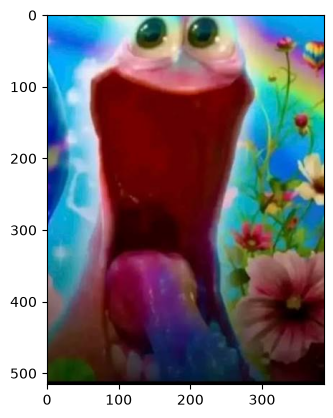

In [4]:
import matplotlib.pyplot as plt

image = plt.imread("photo.jpg")
print(image.shape)

plt.imshow(image)
plt.show()

Розміри: (516, 387)
Кількість каналів: 1


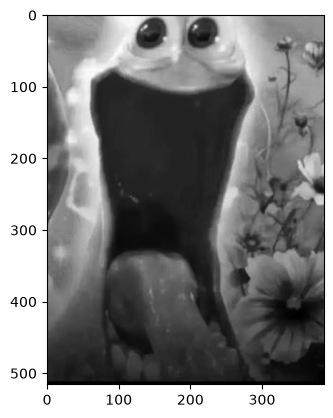

In [7]:
gray = image.mean(axis=2)

print("Розміри:", gray.shape)
print("Кількість каналів:", 1)

plt.imshow(gray, cmap="gray")
plt.show()

In [8]:
mean = gray.mean(axis=0)
centered = gray - mean

print(np.allclose(centered.mean(axis=0), 0))

True


In [9]:
C = np.cov(centered, rowvar=False)
print(C.shape)

(387, 387)


In [10]:
pca_values, pca_vectors = np.linalg.eigh(C)

pca_values = pca_values[::-1]
pca_vectors = pca_vectors[:, ::-1]

print(pca_values[:5])

[519227.6396897  211434.75161411 105535.05125111  47818.93277628
  35216.81807991]


In [11]:
cumulative = np.cumsum(pca_values) / pca_values.sum()

k = 0
for part in cumulative:
    k += 1
    if part >= 0.95:
        break

print("Кількість компонент:", k)

Кількість компонент: 11


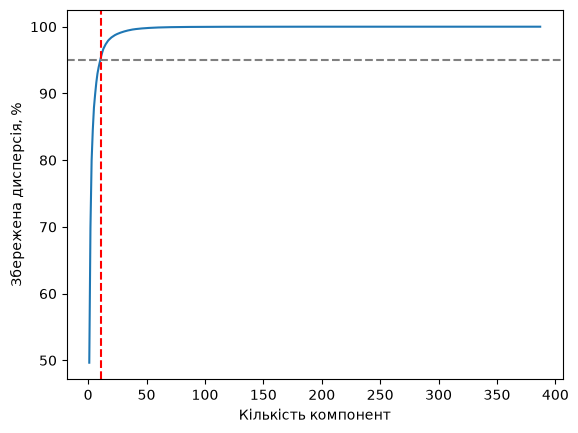

In [12]:
counts = range(1, len(cumulative) + 1)

plt.plot(counts, cumulative * 100)
plt.axhline(95, color="gray", linestyle="--")
plt.axvline(k, color="red", linestyle="--")

plt.xlabel("Кількість компонент")
plt.ylabel("Збережена дисперсія, %")
plt.show()

Розмір після стиснення: (516, 11)
Розмір після відновлення: (516, 387)


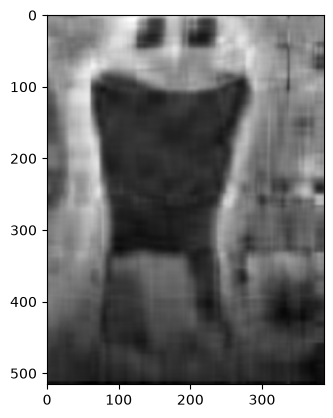

In [13]:
Q = pca_vectors[:, :k]
compressed = centered @ Q
restored = compressed @ Q.T + mean

print("Розмір після стиснення:", compressed.shape)
print("Розмір після відновлення:", restored.shape)

plt.imshow(restored, cmap="gray")
plt.show()

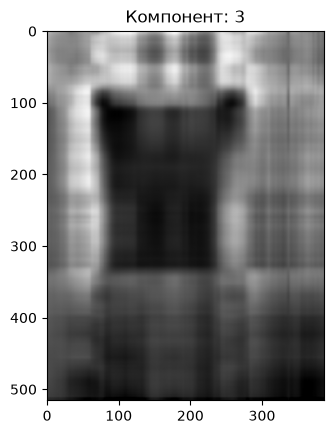

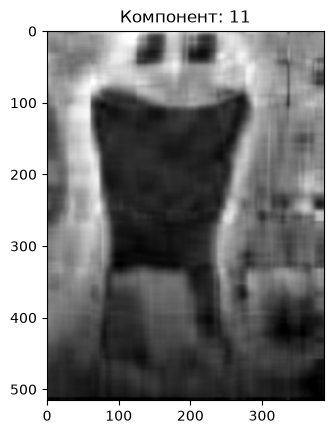

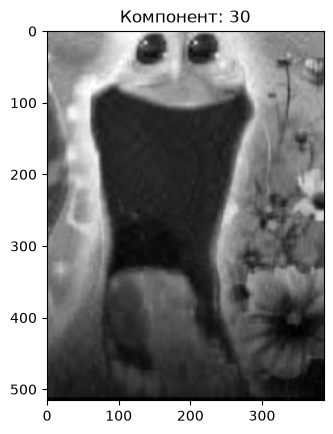

In [14]:
for n in [3, k, 30]:
    Q = pca_vectors[:, :n]
    compressed = centered @ Q
    result = compressed @ Q.T + mean

    plt.imshow(result, cmap="gray", vmin=gray.min(), vmax=gray.max())
    plt.title(f"Компонент: {n}")
    plt.show()

З 3 компонентами зображення сильно розмите. З 11 компонентами - 95% дисперсії - видно ,юільшість основних рис картинки. З 30 компонентами краще видно очі і фон.

In [20]:
message = "Hi"
codes = np.array([ord(char) for char in message])
print(codes)

[ 72 105]


In [21]:


key = np.array([[3, 1],
                [0, 2]])

encrypted = key @ codes
print(encrypted)

[321 210]


In [22]:
def decrypt_message_(encrypted_vector, key_matrix):
    values, P = np.linalg.eig(key_matrix)
    coords = np.linalg.solve(P, encrypted_vector)
    decoded = P @ (coords / values)
    codes = [round(code.real) for code in decoded]
    return "".join(chr(code) for code in codes)

decrypted = decrypt_message_(encrypted, key)
print(decrypted)
print(decrypted == message)

Hi
True


In [18]:
message = "Sigma Boy"
codes = np.array([ord(char) for char in message])
n = len(message)

R = np.random.randint(0, 5, size=(n, n))
key = R.T @ R + np.eye(n)

encrypted = key @ codes
decrypted = decrypt_message_(encrypted, key)

print("Початковий текст:", message)
print("Зашифровані числа:", encrypted)
print("Розшифрований текст:", decrypted)
print("Тексти збігаються:", message == decrypted)

Початковий текст: Sigma Boy
Зашифровані числа: [23620. 34078. 40799. 45355. 32191. 30299. 31206. 22593. 40826.]
Розшифрований текст: Sigma Boy
Тексти збігаються: True
